# EDA: научные публикации arXiv

Чекпойнт 2. Новиков Артемий, Кирилл Лебедев. Куратор: Тимофей Соборнов.

| Данные | Условия |
| --- | --- |
| Объект | Уникальный arXiv ID; версия хранится отдельно |
| Отбор | `cs.IR` (информационный поиск) или `cs.CL` (компьютерная лингвистика), первая подача в январе-марте 2025 года |
| Срез | 6 274 записи, полученные 10.11.2026; названия, аннотации и метаданные |
| Поля | ID и версия; текст; списки авторов и категорий; даты UTC; необязательные DOI, журнальная ссылка и комментарий |
| Границы | Нет полных текстов, библиографии и разметки релевантности. Выводы относятся к этому кварталу и двум областям |

Дата первой подачи не фиксирует содержимое аннотации: API возвращает полученную на дату сбора версию.

<details><summary>Восстановление и запуск</summary>

Python 3.12, доступ к arXiv для первого сбора, без ключей API.

1. `python -m pip install -r requirements-eda.txt`
2. `python scripts/collect_arxiv.py` собирает три месяца в локальный кеш `data/`.
3. `python scripts/collect_arxiv.py --offline` проверяет полноту кеша и хеши XML.
4. Выполнить ноутбук из корня репозитория. После сбора сеть не нужна.

При ошибке предыдущего шага остановиться. Кеш и результаты `reports/` не входят в Git. Скрипт восстанавливает условия отбора, но версии arXiv могут измениться; ячейка загрузки проверяет совпадение с исходным корпусом. При отличии нужно пересмотреть числовые выводы и PDF. Новый кеш задаётся через `--data-dir`, путь к нему в ноутбуке через `ARXIV_DATA_DIR`.

Источник: [arXiv API](https://info.arxiv.org/help/api/user-manual.html). Метаданные: [CC0 и условия доступа](https://info.arxiv.org/help/api/tou.html). Запросы последовательные, по 200 записей, интервал не менее 3,2 секунды.

</details>

In [1]:
from pathlib import Path
import os, sys, time, json, hashlib, re, unicodedata
from collections import Counter, defaultdict
from itertools import combinations
import importlib.metadata

ROOT = Path.cwd()
if not (ROOT / 'scripts/collect_arxiv.py').exists():
    raise FileNotFoundError('Запустите ноутбук из корня research-assistant')
os.environ['MPLCONFIGDIR'] = str(ROOT / '.cache/matplotlib')
(ROOT / '.cache/matplotlib').mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import GroupShuffleSplit
from IPython.display import display, Markdown
from scripts.collect_arxiv import load_dataset

RUN_STARTED = time.perf_counter()
SEED = 42
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlepad': 12, 'figure.dpi': 110, 'savefig.dpi': 155})
FIGURES = ROOT / 'reports/figures'
PROCESSED = ROOT / 'data/processed'
FIGURES.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

def save_figure(name):
    plt.savefig(FIGURES / f'{name}.png', bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close()

versions = {package: importlib.metadata.version(package)
            for package in ['pandas', 'numpy', 'matplotlib', 'requests', 'scipy',
                            'scikit-learn', 'networkx', 'nbformat']}
summary = {'versions': versions, 'seed': SEED}



DATA_DIR = Path(os.environ.get('ARXIV_DATA_DIR', str(ROOT / 'data')))
records, audit_rows = load_dataset(DATA_DIR)
raw = pd.DataFrame(records)
audit = pd.DataFrame(audit_rows).set_index('Месяц')
assert raw['arxiv_id'].is_unique
assert raw['categories'].map(lambda cats: bool(set(cats) & {'cs.IR', 'cs.CL'})).all()
summary.update(n=len(raw), months=len(audit), pages=int(audit['Страниц API'].sum()),
               raw_xml_mib=round(audit['XML, МиБ'].sum(), 2))

REFERENCE_SHA256 = 'd5219a008e80b87af1aa3eb3848b7375a28ed9ddece4ef1e3a3b61adaa20551a'
fingerprint = hashlib.sha256(json.dumps(records, ensure_ascii=False, sort_keys=True,
                                       separators=(',', ':')).encode()).hexdigest()
if fingerprint == REFERENCE_SHA256:
    print('Кеш совпадает с корпусом исходного исследования 10.11.2026.')
else:
    display(Markdown('**Новый корпус.** Метаданные отличаются от сбора 10.11.2026. '
                     'После пересчёта проверьте числовые выводы в Markdown и документ о практической ценности.'))
summary['dataset_sha256'] = fingerprint
display(audit.round(2))

Кеш совпадает с корпусом исходного исследования 10.11.2026.


,Статей,Страниц API,"XML, МиБ","Получено, UTC"
Месяц,,,,
2025-01,1502,8,3.46,2026-11-10T14:31:34.093164+00:00
2025-02,2705,14,6.04,2026-11-10T15:14:22.303695+00:00
2025-03,2067,11,4.62,2026-11-10T15:15:31.011763+00:00


## 1. Качество записей

Пустые строки и списки считаются пропусками. Повторы текста ищутся после приведения регистра и удаления пунктуации. ID без версии должен быть уникальным, даты и основная категория должны согласовываться с отбором.

In [2]:
def is_missing(value):
    if value is None:
        return True
    if isinstance(value, (str, list)):
        return len(value) == 0
    return bool(pd.isna(value))

missing = pd.DataFrame({'Пропусков': {c: int(raw[c].map(is_missing).sum()) for c in raw}})
missing['Доля, %'] = missing['Пропусков'] / len(raw) * 100
normalize_text = lambda text: ' '.join(re.findall(r'\w+', text.casefold()))
normalized_titles = raw['title'].map(normalize_text)
normalized_abstracts = raw['abstract'].map(normalize_text)
duplicate_counts = pd.Series({
    'arxiv_id': int(raw['arxiv_id'].duplicated().sum()),
    'Нормализованное название': int(normalized_titles.duplicated().sum()),
    'Нормализованная аннотация': int(normalized_abstracts.duplicated().sum()),
}, name='Лишних строк')
required = ['arxiv_id', 'versioned_id', 'title', 'abstract', 'authors', 'categories',
            'primary_category', 'published', 'updated']
assert not raw[required].map(is_missing).any().any()
assert raw.apply(lambda r: r['primary_category'] in r['categories'], axis=1).all()
assert raw['version'].ge(1).all()
display(missing.loc[missing['Пропусков'].gt(0)].round(2))
display(duplicate_counts.to_frame())
for label, values in [('Названия', normalized_titles), ('Аннотации', normalized_abstracts)]:
    if values.duplicated(keep=False).any():
        print(label)
        display(raw.loc[values.duplicated(keep=False), ['arxiv_id', 'title']])

doi_normalized = raw['doi'].dropna().str.lower().str.replace(r'^https?://(?:dx\.)?doi\.org/', '', regex=True)
doi_duplicate_rows = doi_normalized[doi_normalized.duplicated(keep=False)]
print('Строк с повторяющимся непустым DOI:', len(doi_duplicate_rows))
if len(doi_duplicate_rows):
    display(raw.loc[doi_duplicate_rows.index, ['arxiv_id', 'title', 'doi']])
summary.update(doi_missing_pct=round(missing.loc['doi', 'Доля, %'],1),
               journal_missing_pct=round(missing.loc['journal_ref', 'Доля, %'],1),
               duplicate_titles=int(duplicate_counts.iloc[1]),
               duplicate_abstracts=int(duplicate_counts.iloc[2]), doi_duplicate_rows=len(doi_duplicate_rows))

,Пропусков,"Доля, %"
doi,5757,91.76
journal_ref,5896,93.98
comment,2694,42.94


,Лишних строк
arxiv_id,0
Нормализованное название,1
Нормализованная аннотация,0


Названия


,arxiv_id,title
3285,2502.14437,Natural Language Generation
5608,2503.16728,Natural Language Generation


Строк с повторяющимся непустым DOI: 0


Для ключа индекса подходит arXiv ID: DOI отсутствует у 91,8% записей. Две публикации с названием `Natural Language Generation` описывают книгу и обзорную статью; удалять запись только по совпадению названия нельзя.

В `comment` отдельно ищутся административная пометка `arXiv admin note: ... withdrawn` и прочие упоминания отзыва. Второй шаблон требует просмотра; отсутствие пометки не подтверждает действующий статус.

In [3]:
df = raw.copy()
df['published'] = pd.to_datetime(df['published'], utc=True, errors='coerce')
df['updated'] = pd.to_datetime(df['updated'], utc=True, errors='coerce')
assert df[['published', 'updated']].notna().all().all()
assert df['updated'].ge(df['published']).all()
assert df['published'].between(pd.Timestamp('2025-01-01',tz='UTC'),
                               pd.Timestamp('2025-04-01',tz='UTC'),inclusive='left').all()

def words(text):
    return re.findall(r"[A-Za-z]+(?:[-'][A-Za-z]+)*|[0-9]+(?:\.[0-9]+)?", text.lower())

df['title_words'] = df['title'].map(lambda s: len(words(s)))
df['abstract_words'] = df['abstract'].map(lambda s: len(words(s)))
df['abstract_chars'] = df['abstract'].str.len()
df['n_authors'] = df['authors'].str.len()
df['n_categories'] = df['categories'].str.len()
df['update_gap_days'] = (df['updated'] - df['published']).dt.total_seconds()/86400
df['month'] = df['published'].dt.strftime('%Y-%m')
df['has_doi'] = df['doi'].notna()
df['has_latex_marker'] = df['abstract'].str.contains(r'\$|\\[A-Za-z]+', regex=True)
df['has_number'] = df['abstract'].str.contains(r'\d', regex=True)
df['has_acronym'] = df['abstract'].str.contains(r'\b[A-Z]{2,}[A-Z0-9-]*\b', regex=True)
df['has_url'] = df['abstract'].str.contains(r'https?://', regex=True)
df['group'] = df['categories'].map(lambda cats: 'cs.IR + cs.CL' if {'cs.IR','cs.CL'}.issubset(cats)
                                  else ('cs.IR без cs.CL' if 'cs.IR' in cats else 'cs.CL без cs.IR'))
ORDER = ['cs.CL без cs.IR','cs.IR без cs.CL','cs.IR + cs.CL']
MONTHS = sorted(df['month'].unique())
EXTRA_STOP = set('paper papers propose proposed proposes present presents show shows study studies work works method methods model models approach approaches result results using use used novel new framework introduce introduces demonstrate demonstrates provide provides significant significantly often address research'.split())
STOPWORDS = set(ENGLISH_STOP_WORDS) | EXTRA_STOP

def content_words(text):
    return [w for w in words(text) if len(w)>=3 and w not in STOPWORDS and not w[0].isdigit()]

title_sets = df['title'].map(lambda s:set(content_words(s)))
abstract_sets = df['abstract'].map(lambda s:set(content_words(s)))
df['title_coverage'] = [len(t & a)/len(t) if t else np.nan for t,a in zip(title_sets,abstract_sets)]
assert df[['title_words','abstract_words','n_authors','n_categories']].gt(0).all().all()
features = ['title_words','abstract_words','n_authors','n_categories','version','update_gap_days']

In [4]:
comments=df['comment'].fillna('')
admin_notice=comments.str.contains(r'arXiv admin note:.*\bwithdrawn\b',case=False,regex=True)
other_marker=comments.str.contains(r'\b(?:withdrawn|withdrawal|withdraw|retracted|retraction)\b',case=False,regex=True)
df['withdrawal_signal']=np.select([admin_notice,other_marker],['admin_notice','other_marker'],default='no_marker')
status_counts=pd.crosstab(df['month'],df['withdrawal_signal']).reindex(index=MONTHS,columns=['admin_notice','other_marker','no_marker'],fill_value=0)
flagged=df[df['withdrawal_signal'].ne('no_marker')]
no_admin=df[~admin_notice]
status_sensitivity=pd.DataFrame({
    'Все статьи':{'n':len(df),'Медиана аннотации':df['abstract_words'].median(),
                  'Доля CL без IR':df['group'].eq(ORDER[0]).mean()},
    'Без admin_notice':{'n':len(no_admin),'Медиана аннотации':no_admin['abstract_words'].median(),
                        'Доля CL без IR':no_admin['group'].eq(ORDER[0]).mean()}})
summary.update(admin_notice_n=int(admin_notice.sum()),withdrawal_other_n=int((other_marker&~admin_notice).sum()),
               withdrawal_candidates_n=len(flagged),
               no_admin_abstract_median=float(no_admin['abstract_words'].median()))
display(status_counts[['admin_notice', 'other_marker']])
display(status_sensitivity.round(3))

withdrawal_signal,admin_notice,other_marker
month,,
2025-01,13,2
2025-02,24,5
2025-03,2,4


,Все статьи,Без admin_notice
n,6274.000,6235.000
Медиана аннотации,170.000,169.000
Доля CL без IR,0.855,0.854


39 административных пометок и 11 других кандидатов требуют отдельного статуса в поисковой выдаче. После исключения административных пометок медиана аннотации меняется с 170 до 169 слов: распределение длин почти не меняется, пригодность источников остаётся отдельным вопросом.

## 2. Длины текстов и выбросы

Счётчик слов учитывает латиницу и числа по выражению в коде; это не токенизатор языковой модели. В признаках разметки используются регулярные выражения, исходный текст сохраняется.

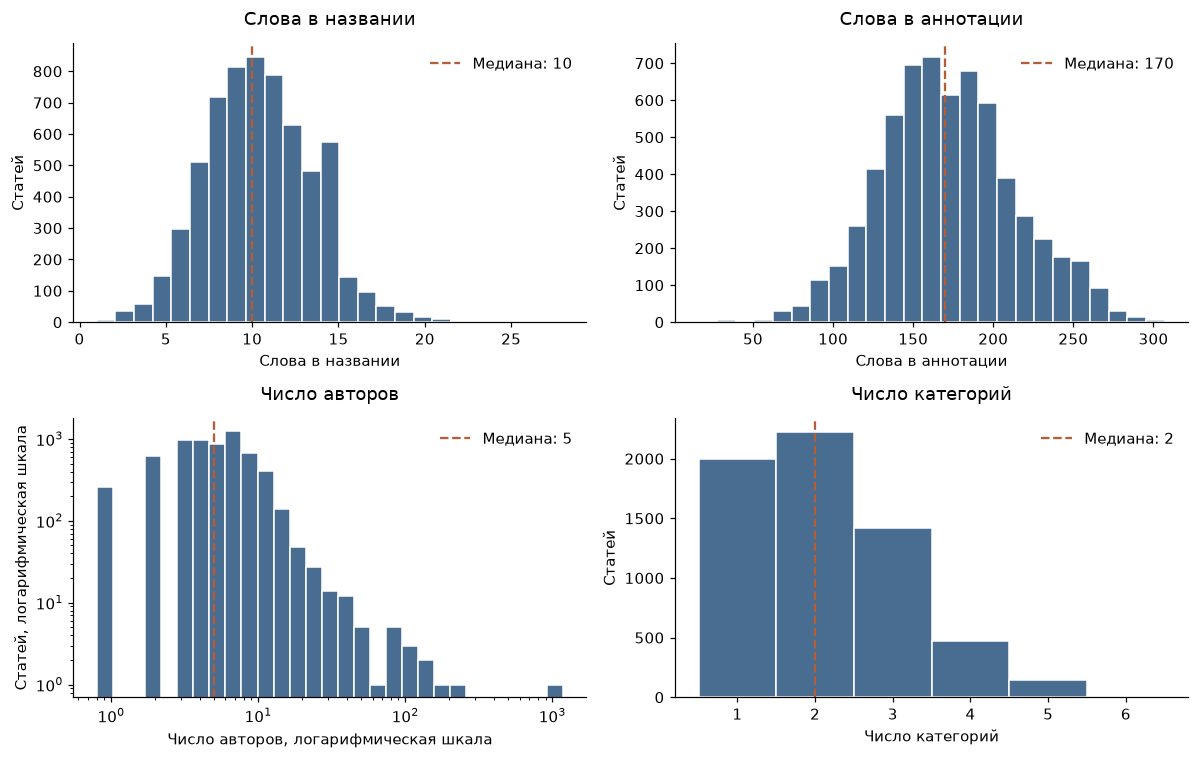

,title_words,abstract_words,n_authors,n_categories,version,update_gap_days
0.00,1.0,16.0,1.0,1.0,1.0,0.0
0.50,10.0,170.0,5.0,2.0,1.0,0.0
0.95,16.0,248.0,12.0,4.0,4.0,388.3
1.00,28.0,307.0,1181.0,6.0,12.0,660.2


,arxiv_id,title,n_authors
1057,2501.14249,Humanity's Last Exam,1181
5854,2503.19786,Gemma 3 Technical Report,216
953,2501.12948,DeepSeek-R1: Incentivizing Reasoning Capabilit...,200


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, column, label in zip(axes.flat,
        ['title_words', 'abstract_words', 'n_authors', 'n_categories'],
        ['Слова в названии', 'Слова в аннотации', 'Число авторов', 'Число категорий']):
    values = df[column]
    bins = (25 if column.endswith('words') else np.arange(values.min() - .5, values.max() + 1.5))
    if column == 'n_authors':
        bins = np.geomspace(.8, values.max() + 1, 30)
    ax.hist(values, bins=bins, color='#486d91', edgecolor='white')
    ax.axvline(values.median(), color='#b45d37', linestyle='--', label=f'Медиана: {values.median():g}')
    ax.set(xlabel=label, ylabel='Статей', title=label)
    if column == 'n_authors':
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlabel('Число авторов, логарифмическая шкала')
        ax.set_ylabel('Статей, логарифмическая шкала')
    ax.legend(frameon=False)
fig.tight_layout()
save_figure('concise_01_distributions')


display(df[features].quantile([0, .5, .95, 1]).round(1))
display(df.nlargest(3, 'n_authors')[['arxiv_id', 'title', 'n_authors']])
summary.update(abstract_median=float(df['abstract_words'].median()),
               abstract_p95=float(df['abstract_words'].quantile(.95)),
               abstract_min=int(df['abstract_words'].min()), abstract_max=int(df['abstract_words'].max()),
               title_median=float(df['title_words'].median()), authors_median=float(df['n_authors'].median()),
               authors_max=int(df['n_authors'].max()), authors_p95=float(df['n_authors'].quantile(.95)))

Аннотации содержат 16-307 слов, 95-й перцентиль равен 248. Для проверки поиска нужны короткие и длинные тексты. У 95% статей не больше 12 авторов; максимум 1 181 относится к `Humanity's Last Exam`. Такой список требует проверки, но не автоматического удаления.

## 3. Категории, месяцы и версии

Группы ниже взаимоисключающие: CL без IR, IR без CL, обе категории. Другие категории у этих статей сохраняются. Состав корпуса сопоставляется по месяцам; версия относится к дате сбора.

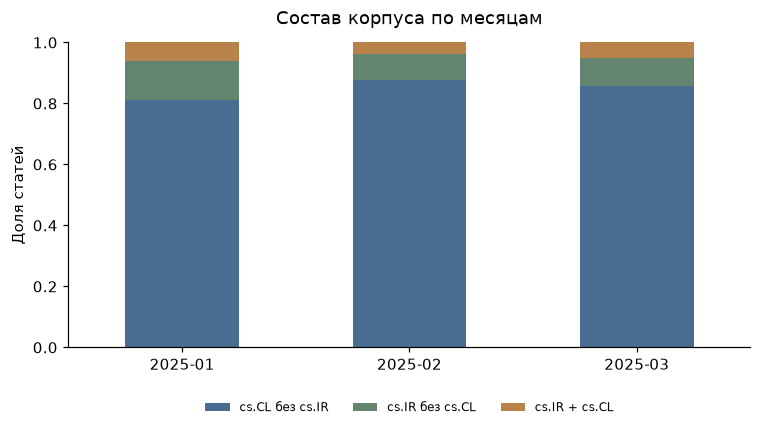

,articles,abstract_median,revised_share,CL_only_share
month,,,,
2025-01,1502,171.0,0.442,0.812
2025-02,2705,169.0,0.554,0.877
2025-03,2067,169.0,0.470,0.858


,Статей
group,
cs.CL без cs.IR,5364
cs.IR без cs.CL,606
cs.IR + cs.CL,304


In [6]:
group_counts = df['group'].value_counts().reindex(ORDER)
monthly_groups = pd.crosstab(df['month'], df['group']).reindex(index=MONTHS, columns=ORDER, fill_value=0)
monthly_shares = monthly_groups.div(monthly_groups.sum(axis=1), axis=0)
monthly = df.groupby('month').agg(
    articles=('arxiv_id', 'size'), abstract_median=('abstract_words', 'median'),
    revised_share=('version', lambda s: s.gt(1).mean()))
monthly['CL_only_share'] = monthly_shares[ORDER[0]]
fig, ax = plt.subplots(figsize=(8, 3.6))
monthly_shares.plot.bar(stacked=True, ax=ax, color=['#486d91', '#63846e', '#b7834b'])
ax.set(xlabel='', ylabel='Доля статей', ylim=(0, 1), title='Состав корпуса по месяцам')
ax.tick_params(axis='x', rotation=0)
ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(.5, -.14), ncol=3)
save_figure('concise_02_composition')
display(monthly.round(3))
display(group_counts.rename('Статей').to_frame())
summary.update(
    both=int(group_counts[ORDER[2]]), revised_pct=round(df['version'].gt(1).mean()*100, 1),
    updated_later=int(df['updated'].ge(pd.Timestamp('2025-04-01', tz='UTC')).sum()),
    revised_gap_median=float(df.loc[df['version'].gt(1), 'update_gap_days'].median()))

IR без CL составляет лишь 606 из 6 274 статей, поэтому общая метрика может скрыть ошибки на IR-запросах. Медианы длины аннотаций по месяцам почти одинаковы: 171/169/169 слов. Половина записей имеет версию выше первой, 2 526 обновлены после квартала; для временного теста нужны тексты доступных тогда версий.

## 4. Связи признаков

Ранговая корреляция Спирмена рассчитывается для корпуса и после исключения верхнего 1% авторских списков. Исключение используется только для проверки чувствительности.

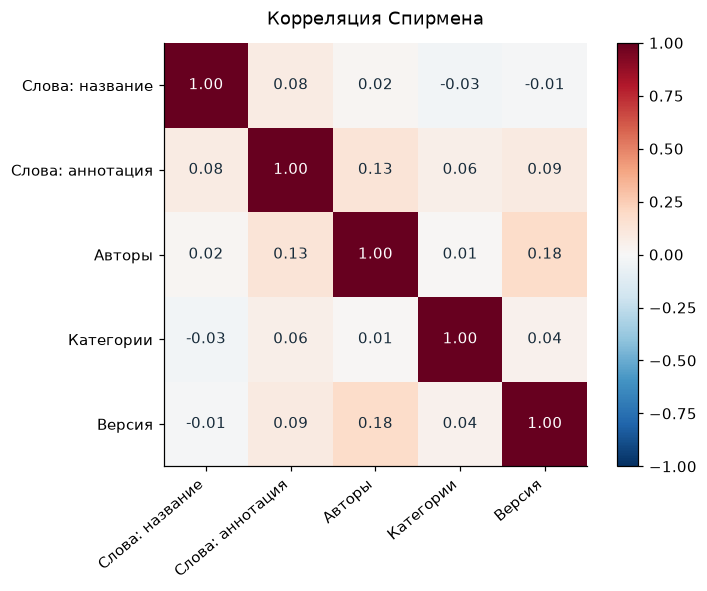

Максимальный |rho| между разными признаками: 0.184
Максимальное изменение без верхнего 1%: 0.005


In [7]:
columns = ['title_words', 'abstract_words', 'n_authors', 'n_categories', 'version']
labels = ['Слова: название', 'Слова: аннотация', 'Авторы', 'Категории', 'Версия']
corr = df[columns].corr(method='spearman')
trimmed = df[df['n_authors'].le(df['n_authors'].quantile(.99))]
trimmed_corr = trimmed[columns].corr(method='spearman')
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(columns)), labels, rotation=40, ha='right')
ax.set_yticks(range(len(columns)), labels)
for i in range(len(columns)):
    for j in range(len(columns)):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center',
                color='white' if abs(corr.iloc[i,j]) > .65 else '#172b3a')
ax.set_title('Корреляция Спирмена')
fig.colorbar(im, ax=ax, fraction=.046)
save_figure('concise_03_correlations')
non_diagonal = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
summary.update(rho_max_abs=float(non_diagonal.abs().max()),
               max_rho_change=float((corr-trimmed_corr).abs().max().max()))
print('Максимальный |rho| между разными признаками:', round(summary['rho_max_abs'], 3))
print('Максимальное изменение без верхнего 1%:', round(summary['max_rho_change'], 3))

Связи слабы: максимальный |rho| равен 0,184 и меняется не более чем на 0,005 при проверке выбросов. Число авторов и версию нельзя использовать как подтверждённый показатель качества статьи.

## 5. Лексика и обработка текста

Для лексических сравнений удаляются английские стоп-слова и слова описания исследования (`STOPWORDS` в коде). Доля документов с термином сравнивается между непересекающимися IR и CL: `log2(((IR_count+0.5)/(IR_n+1)) / ((CL_count+0.5)/(CL_n+1)))`. Включены термины с суммарной частотой не менее 20 документов.

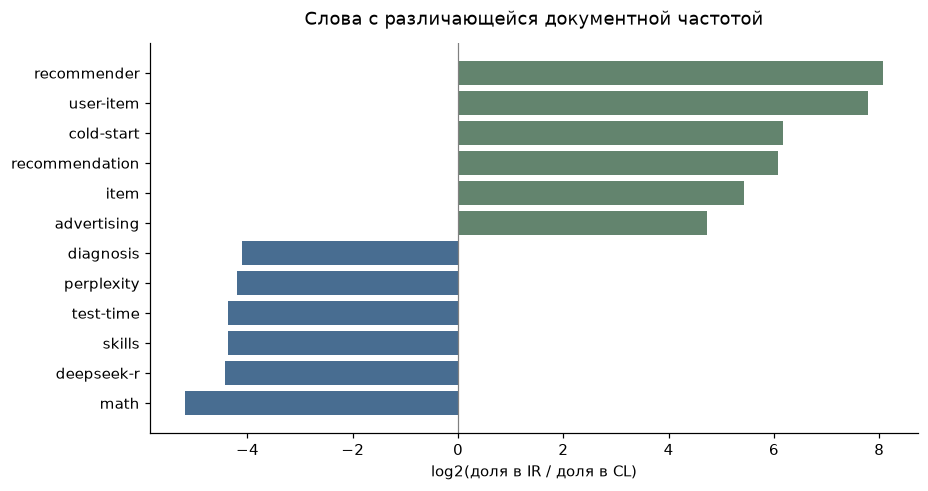

In [8]:
texts = (df['title'] + ' ' + df['abstract']).tolist()
term_vectorizer=CountVectorizer(tokenizer=content_words,token_pattern=None,lowercase=False,
                                min_df=2,max_features=50000,binary=False)
T=term_vectorizer.fit_transform(texts)
terms=term_vectorizer.get_feature_names_out()
D=T.copy();D.data[:]=1
ir_mask=df['group'].eq(ORDER[1]).to_numpy()
cl_mask=df['group'].eq(ORDER[0]).to_numpy()
ir_docs=np.asarray(D[ir_mask].sum(axis=0)).ravel()
cl_docs=np.asarray(D[cl_mask].sum(axis=0)).ravel()
log_ratio=np.log2(((ir_docs+.5)/(ir_mask.sum()+1))/((cl_docs+.5)/(cl_mask.sum()+1)))
lexical=pd.DataFrame({'term':terms,'IR_docs':ir_docs,'CL_docs':cl_docs,'log2_IR_CL':log_ratio})
lexical=lexical[(lexical['IR_docs']+lexical['CL_docs']).ge(20)]
selected=pd.concat([lexical.nsmallest(6,'log2_IR_CL'),lexical.nlargest(6,'log2_IR_CL')]).sort_values('log2_IR_CL')
fig,ax=plt.subplots(figsize=(9,4.6))
ax.barh(selected['term'],selected['log2_IR_CL'],color=np.where(selected['log2_IR_CL']>0,'#63846e','#486d91'))
ax.axvline(0,color='gray',linewidth=.8)
ax.set(xlabel='log2(доля в IR / доля в CL)',title='Слова с различающейся документной частотой')
save_figure('concise_04_lexicon')
summary['ir_terms']=', '.join(lexical.nlargest(5,'log2_IR_CL')['term'])
summary['cl_terms']=', '.join(lexical.nsmallest(5,'log2_IR_CL')['term'])

In [9]:
all_tokens = [content_words(text) for text in texts]
vocabulary_df, token_frequency = Counter(), Counter()
for tokens in all_tokens:
    vocabulary_df.update(set(tokens))
    token_frequency.update(tokens)
rare = {word for word, count in vocabulary_df.items() if count <= 2}
summary.update(
    rare_vocab_pct=100*len(rare)/len(vocabulary_df),
    rare_token_pct=100*sum(token_frequency[w] for w in rare)/sum(token_frequency.values()))
jan_vocab = {word for i in np.flatnonzero(df['month'].eq('2025-01')) for word in all_tokens[i]}
novelty = []
for month in MONTHS:
    tokens = [w for i in np.flatnonzero(df['month'].eq(month)) for w in all_tokens[i]]
    novelty.append({'Месяц': month, 'Слов вне январского словаря, %': 100*sum(w not in jan_vocab for w in tokens)/len(tokens)})
display(pd.DataFrame(novelty).set_index('Месяц').round(2))
print(f"Редкие слова: {summary['rare_vocab_pct']:.1f}% словаря, {summary['rare_token_pct']:.1f}% употреблений")

,"Слов вне январского словаря, %"
Месяц,
2025-01,0.00
2025-02,7.51
2025-03,7.45


Редкие слова: 69.3% словаря, 6.0% употреблений


IR выделяется лексикой рекомендаций, CL лексикой языковых моделей и рассуждений. Обе области нужны в разметке запросов. Слова из одной-двух статей дают 69,3% словаря, но только 6% употреблений: их фильтрация может потерять редкие названия методов. В марте 7,45% употреблений отсутствуют в январском словаре; временной тест должен учитывать новые термины.

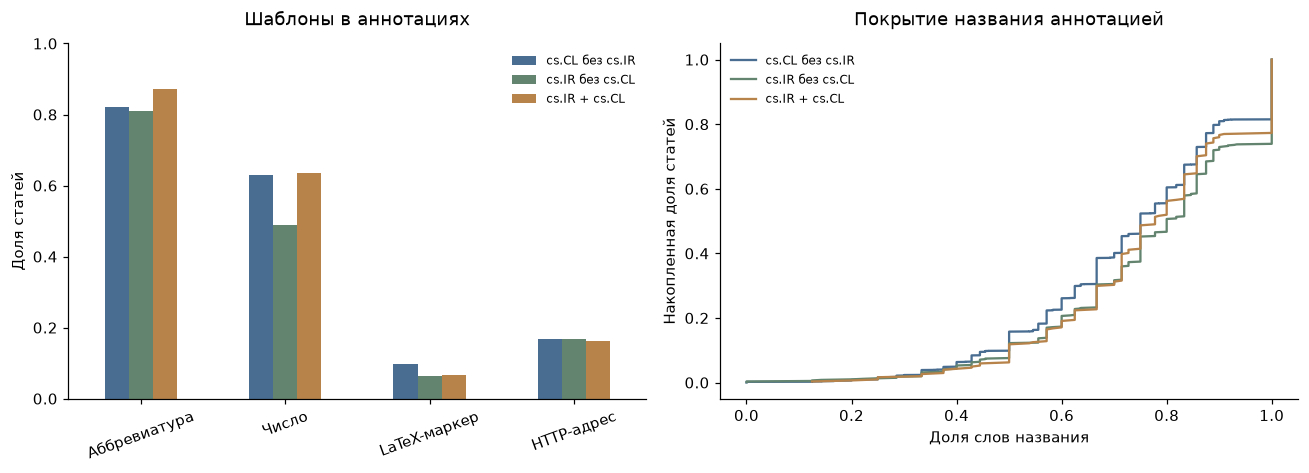

In [10]:
marker_cols=['has_acronym','has_number','has_latex_marker','has_url']
marker_names=['Аббревиатура','Число','LaTeX-маркер','HTTP-адрес']
marker_rates=df.groupby('group')[marker_cols].mean().reindex(ORDER)
fig,axes=plt.subplots(1,2,figsize=(12,4.4))
marker_rates.set_axis(marker_names,axis=1).T.plot.bar(ax=axes[0],color=['#486d91','#63846e','#b7834b'])
axes[0].set(title='Шаблоны в аннотациях',ylabel='Доля статей',xlabel='',ylim=(0,1))
axes[0].tick_params(axis='x',rotation=20);axes[0].legend(fontsize=8,frameon=False)
for group,color in zip(ORDER,['#486d91','#63846e','#b7834b']):
    vals=np.sort(df.loc[df['group'].eq(group),'title_coverage'].dropna())
    axes[1].plot(vals,np.arange(1,len(vals)+1)/len(vals),label=group,color=color)
axes[1].set(title='Покрытие названия аннотацией',xlabel='Доля слов названия',ylabel='Накопленная доля статей')
axes[1].legend(fontsize=8,frameon=False)
fig.tight_layout();save_figure('concise_05_text_markers')
summary.update(latex_n=int(df['has_latex_marker'].sum()),latex_pct=round(df['has_latex_marker'].mean()*100,1),
               acronym_pct=round(df['has_acronym'].mean()*100,1),number_pct=round(df['has_number'].mean()*100,1),
               title_coverage_median=round(float(df['title_coverage'].median()),3),
               low_title_coverage_pct=round(df['title_coverage'].lt(.5).mean()*100,1))

Аббревиатуры обнаружены в 82,4% аннотаций, числа в 61,6%, LaTeX-маркеры в 9,3%. Удалять их без проверки поисковых запросов нельзя. У 9,4% статей аннотация содержит меньше половины содержательных слов названия: поля стоит индексировать раздельно. Покрытие измеряет точные совпадения слов, без синонимов и лемматизации.

## 6. Близкие тексты

TF-IDF увеличивает вес редких слов; косинус сравнивает лексические векторы. Параметры заданы в коде. Сама статья исключается из соседей; для уникальных пар проверяются пороги 0,5-0,9. Пары выше порога требуют просмотра, а не автоматического удаления.

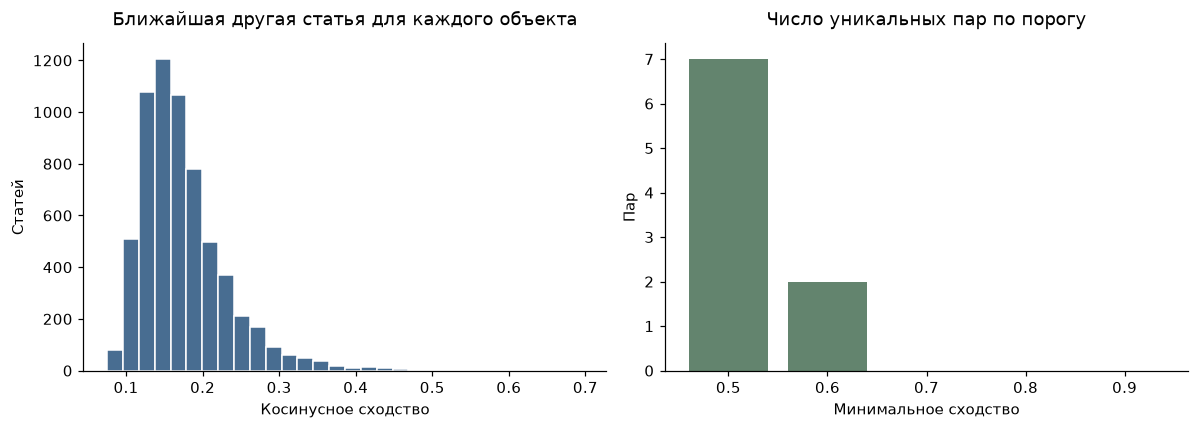

In [11]:
tfidf=TfidfVectorizer(tokenizer=content_words,token_pattern=None,lowercase=False,
                      ngram_range=(1,2),min_df=2,max_df=.95,max_features=40000,
                      sublinear_tf=True,dtype=np.float32)
X=tfidf.fit_transform(texts)
thresholds=np.array([.5,.6,.7,.8,.9])
threshold_counts=np.zeros(len(thresholds),dtype=np.int64)
nearest_scores=np.empty(len(df),dtype=np.float32)
candidates=[]
for begin in range(0,len(df),256):
    finish=min(begin+256,len(df))
    scores=cosine_similarity(X[begin:finish],X)
    scores[np.arange(finish-begin),np.arange(begin,finish)]=-1
    nearest_scores[begin:finish]=scores.max(axis=1)
    for local,global_idx in enumerate(range(begin,finish)):
        row=scores[local,global_idx+1:]
        threshold_counts += (row[:,None]>=thresholds).sum(axis=0)
        for offset in np.flatnonzero(row>=.6):
            j=global_idx+1+int(offset)
            candidates.append((global_idx,j,float(row[offset])))
pairs=pd.DataFrame(candidates,columns=['i','j','word_cosine']).sort_values('word_cosine',ascending=False)
threshold_table=pd.DataFrame({'threshold':thresholds,'pairs':threshold_counts})
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].hist(nearest_scores,bins=30,color='#486d91',edgecolor='white')
axes[0].set(title='Ближайшая другая статья для каждого объекта',xlabel='Косинусное сходство',ylabel='Статей')
axes[1].bar(thresholds.astype(str),threshold_counts,color='#63846e')
axes[1].set(title='Число уникальных пар по порогу',xlabel='Минимальное сходство',ylabel='Пар')
fig.tight_layout();save_figure('concise_06_similarity')
summary.update(near_pairs_06=int(threshold_counts[1]),near_pairs_08=int(threshold_counts[3]),
               nearest_median=round(float(np.median(nearest_scores)),3),
               tfidf_features=int(X.shape[1]))

In [12]:
def normalize_author(name):
    return ' '.join(unicodedata.normalize('NFKC', name).casefold().split())

author_sets = [{normalize_author(a) for a in authors} for authors in df['authors']]
review = []
for row in pairs.itertuples():
    a, b = df.iloc[int(row.i)], df.iloc[int(row.j)]
    review.append({'ID 1': a['arxiv_id'], 'ID 2': b['arxiv_id'],
                   'Косинус': row.word_cosine,
                   'Общих имён авторов': len(author_sets[int(row.i)] & author_sets[int(row.j)])})
display(pd.DataFrame(review).round(3))

,ID 1,ID 2,Косинус,Общих имён авторов
0,2501.13608,2502.09155,0.696,3
1,2503.23032,2503.23040,0.630,4


Порог 0,6 выделил две пары, 0,8 ни одной. В [2501.13608](https://arxiv.org/abs/2501.13608) и [2502.09155](https://arxiv.org/abs/2502.09155) описаны близкие приложения рекомендаций с учётом загрязнения воздуха. [2503.23032](https://arxiv.org/abs/2503.23032) и [2503.23040](https://arxiv.org/abs/2503.23040) воспроизводят **разные** работы, но используют похожие формулировки об экспериментах. Высокое лексическое сходство не подтверждает дублирование.

## 7. Авторские связи и разбиение

В графе узлы соответствуют статьям, ребро означает общую строку имени после нормализации регистра и пробелов. Совпадение имени не подтверждает совпадение человека. Компонента связности объединяет статьи, между которыми есть путь.

Сравниваются случайные 80/20, январь-февраль / март и разбиение по авторским компонентам. Для случайного и группового вариантов используются seed 0/1/2/3/42. В групповом варианте 20% относится к числу компонент, а не статей.

In [13]:
author_to_papers=defaultdict(set)
for idx,names in enumerate(author_sets):
    for name in names:
        if name: author_to_papers[name].add(idx)
edge_weights=Counter()
for indices in author_to_papers.values():
    for a,b in combinations(sorted(indices),2): edge_weights[(a,b)]+=1
G=nx.Graph();G.add_nodes_from(range(len(df)))
G.add_weighted_edges_from((a,b,w) for (a,b),w in edge_weights.items())
components=sorted(nx.connected_components(G),key=len,reverse=True)
component_sizes=np.array([len(c) for c in components])
component_id={node:i for i,c in enumerate(components) for node in c}
sensitivity=[]
for cap in [20,50,100,None]:
    nodes=df.index if cap is None else df.index[df['n_authors'].le(cap)]
    sub=G.subgraph(nodes)
    largest=max((len(c) for c in nx.connected_components(sub)),default=0)
    sensitivity.append({'Максимум авторов':str(cap) if cap else 'Без ограничения',
                        'Узлов':len(sub),'Доля крупнейшей компоненты':largest/len(sub)})
sensitivity=pd.DataFrame(sensitivity)
summary.update(author_edges=G.number_of_edges(),author_components=len(components),
               author_isolated_pct=round(sum(G.degree(i)==0 for i in G)/len(G)*100,1),
               largest_author_component=len(components[0]),largest_author_component_pct=round(len(components[0])/len(G)*100,1))
display(sensitivity.round(3))

,Максимум авторов,Узлов,Доля крупнейшей компоненты
0,20,6196,0.607
1,50,6258,0.626
2,100,6267,0.629
3,Без ограничения,6274,0.637


,"Близкий текст, среднее %",Максимум %
split,,
Временное: март,0.000,0.000
Компоненты авторов,0.000,0.000
Случайное 80/20,0.032,0.159


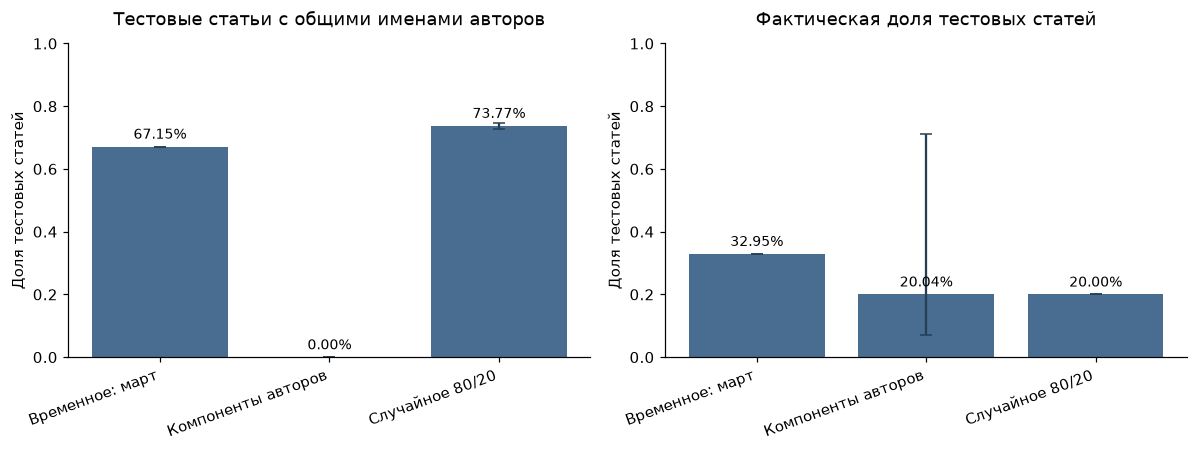

In [14]:
near_G=nx.Graph();near_G.add_nodes_from(range(len(df)))
near_G.add_edges_from((int(r.i),int(r.j)) for r in pairs.itertuples())

def split_diagnostics(train,test,label,seed):
    train_set=set(map(int,train));test_set=set(map(int,test))
    assert not train_set & test_set
    author_overlap=np.mean([bool(set(G.neighbors(i)) & train_set) for i in test_set])
    near_overlap=np.mean([bool(set(near_G.neighbors(i)) & train_set) for i in test_set])
    return {'split':label,'seed':seed,'train_n':len(train_set),'test_n':len(test_set),
            'test_share':len(test_set)/len(df),'shared_author_share':author_overlap,
            'near_text_share':near_overlap}

split_rows=[]
component_labels=np.array([component_id[i] for i in range(len(df))])
for seed in [0,1,2,3,42]:
    order=np.random.default_rng(seed).permutation(len(df));cut=int(.8*len(df))
    split_rows.append(split_diagnostics(order[:cut],order[cut:],'Случайное 80/20',seed))
    splitter=GroupShuffleSplit(n_splits=1,test_size=.2,random_state=seed)
    train,test=next(splitter.split(df,groups=component_labels))
    row=split_diagnostics(train,test,'Компоненты авторов',seed)
    assert row['shared_author_share']==0
    split_rows.append(row)
train=np.flatnonzero(df['month'].ne('2025-03'))
test=np.flatnonzero(df['month'].eq('2025-03'))
split_rows.append(split_diagnostics(train,test,'Временное: март',SEED))
split_results=pd.DataFrame(split_rows)
split_summary=split_results.groupby('split')[['test_share','shared_author_share','near_text_share']].agg(['mean','min','max'])
display((split_results.groupby('split')['near_text_share'].agg(['mean', 'max'])*100).rename(columns={'mean':'Близкий текст, среднее %', 'max':'Максимум %'}).round(3))
fig,axes=plt.subplots(1,2,figsize=(11,4.2))
for ax,column,title in zip(axes,['shared_author_share','test_share'],['Тестовые статьи с общими именами авторов','Фактическая доля тестовых статей']):
    stats=split_results.groupby('split')[column].agg(['mean','min','max'])
    x=np.arange(len(stats))
    ax.bar(x,stats['mean'],color='#486d91')
    ax.errorbar(x,stats['mean'],yerr=[stats['mean']-stats['min'],stats['max']-stats['mean']],fmt='none',ecolor='#263f53',capsize=4)
    ax.set_xticks(x,stats.index,rotation=20,ha='right')
    ax.set(title=title,ylabel='Доля тестовых статей',ylim=(0,1))
    for position,value in enumerate(stats['mean']):
        ax.text(position,value+ax.get_ylim()[1]*.025,f'{value:.2%}',ha='center',fontsize=9)
fig.tight_layout();save_figure('concise_07_splits')
random_rows=split_results[split_results['split'].eq('Случайное 80/20')]
group_rows=split_results[split_results['split'].eq('Компоненты авторов')]
summary.update(random_shared_author_pct=round(random_rows['shared_author_share'].mean()*100,1),
               random_near_text_pct=round(random_rows['near_text_share'].mean()*100,3),
               group_test_share_min=round(group_rows['test_share'].min()*100,1),
               group_test_share_max=round(group_rows['test_share'].max()*100,1))

Крупнейшая авторская компонента включает 63,7% статей; исключение списков более 20 авторов оставляет около 60%, поэтому эффект не сводится к одной коллективной работе. При случайном разбиении 73,8% тестовых статей имеют общее имя с обучающей частью; близкий текст по порогу 0,6 встречается у 0,032%.

Группировка устраняет авторское пересечение, но фактический размер теста меняется от 7% до 71%. Совпадение авторов само по себе не доказывает утечку релевантности. Перед обучением нужно выбрать правило разбиения и проверить размер и тематики частей.

## 8. Аугментации запросов

Проверяются три преобразования: удаление 10% слов, перестановка одной соседней пары и опечатка в одном слове. Названия статей служат прокси коротких запросов; реальных запросов и размеченных пар релевантности **0**. Для каждого названия создаётся по одному варианту каждого типа, `seed=42`.

Эвристически защищены токены с цифрами, минимум двумя заглавными буквами и отрицания `no/not/never/without/neither/nor`. Опечатки их обходят. Измеряются доля изменённых названий, потеря защищённых токенов и косинус между исходным и изменённым TF-IDF-векторами. Эти проверки не доказывают сохранение смысла и не измеряют качество поиска.

In [15]:
NEGATIONS = {'no', 'not', 'never', 'without', 'neither', 'nor'}

def protected(token):
    return (any(ch.isdigit() for ch in token)
            or sum(ch.isupper() for ch in token) >= 2
            or bool(set(words(token)) & NEGATIONS))

def augment_title(title, method, rng):
    tokens = title.split()
    if method == 'Удаление слов':
        keep = rng.random(len(tokens)) >= .1
        if not keep.any():
            keep[0] = True
        tokens = [word for word, retain in zip(tokens, keep) if retain]
    elif method == 'Перестановка':
        if len(tokens) > 1:
            i = int(rng.integers(len(tokens)-1))
            tokens[i], tokens[i+1] = tokens[i+1], tokens[i]
    else:
        eligible = [i for i, token in enumerate(tokens)
                    if not protected(token) and len(re.findall('[A-Za-z]', token)) >= 5]
        if eligible:
            i = int(rng.choice(eligible))
            positions = [j for j in range(1, len(tokens[i])-1) if tokens[i][j].isalpha()]
            j = int(rng.choice(positions))
            tokens[i] = tokens[i][:j] + tokens[i][j+1:]
    return ' '.join(tokens)

titles = df['title'].tolist()
Q = tfidf.transform(titles)
valid = np.asarray(Q.getnnz(axis=1)).ravel() > 0
augmentation_rows, augmentation_examples = [], []
for method in ['Удаление слов', 'Перестановка', 'Опечатка']:
    rng = np.random.default_rng(SEED)
    variants = [augment_title(title, method, rng) for title in titles]
    lost = np.array([bool({t for t in a.split() if protected(t)} - set(b.split()))
                     for a, b in zip(titles, variants)])
    changed = np.array([a != b for a, b in zip(titles, variants)])
    similarity = np.asarray(Q.multiply(tfidf.transform(variants)).sum(axis=1)).ravel()
    augmentation_rows.append({
        'Метод': method, 'Изменено, %': changed.mean()*100,
        'Потеря защищённых токенов, %': lost.mean()*100,
        'Медиана косинуса': np.median(similarity[valid]),
    })
    examples = np.flatnonzero(lost if lost.any() else changed)
    i = int(examples[0])
    augmentation_examples.append({'Метод': method, 'ID': df.iloc[i]['arxiv_id'],
                                  'Исходное название': titles[i], 'Вариант': variants[i]})
augmentation_stats = pd.DataFrame(augmentation_rows).set_index('Метод')
display(augmentation_stats.round(3))
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame(augmentation_examples).set_index('Метод'))
print('Названий с ненулевым исходным TF-IDF-вектором:', int(valid.sum()), 'из', len(df))
summary['augmentation'] = augmentation_stats.reset_index().to_dict(orient='records')

,"Изменено, %","Потеря защищённых токенов, %",Медиана косинуса
Метод,,,
Удаление слов,64.409,11.938,1.00
Перестановка,99.984,0.000,1.00
Опечатка,99.936,0.000,0.91


,ID,Исходное название,Вариант
Метод,,,
Удаление слов,2501.01031,ValuesRAG: Enhancing Cultural Alignment Through Retrieval-Augmented Contextual Learning,ValuesRAG: Enhancing Cultural Through Contextual Learning
Перестановка,2501.00684,IGC: Integrating a Gated Calculator into an LLM to Solve Arithmetic Tasks Reliably and Efficiently,IGC: a Integrating Gated Calculator into an LLM to Solve Arithmetic Tasks Reliably and Efficiently
Опечатка,2501.00684,IGC: Integrating a Gated Calculator into an LLM to Solve Arithmetic Tasks Reliably and Efficiently,IGC: Integraing a Gated Calculator into an LLM to Solve Arithmetic Tasks Reliably and Efficiently


Названий с ненулевым исходным TF-IDF-вектором: 6269 из 6274


Удаление слов потеряло защищённые токены в 11,9% названий. Медианный косинус при удалении и перестановке равен 1: текущий анализатор может не заметить изменение текста, поэтому отбирать положительные пары только по косинусу нельзя.

| Способ | Решение |
| --- | --- |
| Удаление слов | Не использовать для положительных обучающих пар: могут теряться числа, термины и отрицания |
| Перестановка | Не принимать без ручной проверки: сохранение словаря не гарантирует сохранения отношения между терминами |
| Опечатка | Подходит для стресс-теста запросов с опечатками. Для обучения нужна проверка релевантности; названия методов могут измениться и без потери защищённых токенов |

Исходные статьи не аугментируются. Преобразования пока не включаются в обучение: в корпусе нет разметки, позволяющей проверить сохранение релевантности.

## 9. Решения для следующего этапа

- Использовать arXiv ID и версию; сохранять пометки об отзыве источника.
- Сравнить совместный и раздельный поиск по названию и аннотации; проверить числа, аббревиатуры и редкие термины.
- Разметить запросы IR и CL, включая короткие тексты и новые названия методов; проверить близкие пары вручную.
- Проверить опечатки в пользовательских запросах; не размечать автоматически искажённые запросы как релевантные.
- Зафиксировать разбиение до обучения. Словарь и преобразования для оценки строить только на обучающей части.

Качество поиска ещё не измерено: для Recall@k и nDCG@k нужна разметка релевантности. Практическая ценность проверяется отдельно по времени до подтверждения утверждения и корректности источников; план изложен в `practical_value.pdf`.

In [16]:
df.to_json(PROCESSED / 'articles.jsonl', orient='records', lines=True,
           force_ascii=False, date_format='iso')
summary.update(figures=7, analysis_seconds=round(time.perf_counter()-RUN_STARTED, 2))
(ROOT / 'reports/eda_summary.json').write_text(
    json.dumps(summary, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
print(f"Готово: {len(df)} статей, {summary['figures']} графиков.")

Готово: 6274 статей, 7 графиков.
